### importing libraries and raw data

In [2]:
import numpy as np
import pandas as pd
import re
import nltk
from nltk.stem.porter import PorterStemmer

# Initialize the Porter Stemmer for text normalization
stemmer = PorterStemmer()

# Load the datasets
print("Loading data...")
try:
    train_df = pd.read_csv('data/train.csv', encoding='ISO-8859-1')
    desc_df = pd.read_csv('data/product_descriptions.csv', encoding='ISO-8859-1')
    
    print("Train dataset shape:", train_df.shape)
    print("Description dataset shape:", desc_df.shape)
    
    # Merge datasets based on product_uid
    df = pd.merge(train_df, desc_df, on='product_uid', how='left')
    print("Merged dataset shape:", df.shape)
    
    # Show the first few rows to verify
    print("\nFirst 5 rows of merged data:")
    print(df[['product_uid', 'search_term', 'product_title', 'product_description']].head())

except FileNotFoundError:
    print("Error: Make sure 'train.csv' and 'product_descriptions.csv' are in the same folder.")

Loading data...
Train dataset shape: (74067, 5)
Description dataset shape: (124428, 2)
Merged dataset shape: (74067, 6)

First 5 rows of merged data:
   product_uid         search_term  \
0       100001       angle bracket   
1       100001           l bracket   
2       100002           deck over   
3       100005    rain shower head   
4       100005  shower only faucet   

                                       product_title  \
0                  Simpson Strong-Tie 12-Gauge Angle   
1                  Simpson Strong-Tie 12-Gauge Angle   
2  BEHR Premium Textured DeckOver 1-gal. #SC-141 ...   
3  Delta Vero 1-Handle Shower Only Faucet Trim Ki...   
4  Delta Vero 1-Handle Shower Only Faucet Trim Ki...   

                                 product_description  
0  Not only do angles make joints stronger, they ...  
1  Not only do angles make joints stronger, they ...  
2  BEHR Premium Textured DECKOVER is an innovativ...  
3  Update your bathroom with the Delta Vero Singl...  
4  Update

### text preprocessing

In [3]:
# Function to clean and normalize text columns
def clean_text(text):
    if isinstance(text, str):
        # 1. Convert to lowercase
        text = text.lower()
        
        # 2. Normalize common units (important for Home Depot data)
        text = re.sub(r'(\d+)\s*(inches|inch|in|in\.)(?=\b|\d)', r'\1 inch ', text)
        text = re.sub(r'(\d+)\s*(feet|foot|ft|ft\.)(?=\b|\d)', r'\1 foot ', text)
        text = re.sub(r'(\d+)\s*(pounds|pound|lbs|lb|lb\.)(?=\b|\d)', r'\1 pound ', text)
        text = re.sub(r'(\d+)\s*(volts|volt|v)(?=\b|\d)', r'\1 volt ', text)
        
        # 3. Separate numbers from 'x' (e.g., 2x4 became 2 x 4)
        text = re.sub(r'(\d+)(x|\s*x\s*)(\d+)', r'\1 x \3', text)
        
        # 4. Remove punctuation and keep letters and numbers
        text = re.sub(r'[^a-zA-Z0-9\s]', ' ', text)
        
        # 5. Tokenize and apply Porter Stemming
        words = text.split()
        stemmed_words = [stemmer.stem(w) for w in words]
        
        return " ".join(stemmed_words)
    else:
        return ""

# Test the function with a sample string to make sure it works
sample_text = "Baseline 2x4 12-Inches bracket!"
print("Original:", sample_text)
print("Cleaned: ", clean_text(sample_text))

Original: Baseline 2x4 12-Inches bracket!
Cleaned:  baselin 2 x 4 12 inch bracket


In [4]:
print("Applying text cleaning on the dataset... This may take a moment.")

# Apply the cleaning function to all text columns
df['clean_search_term'] = df['search_term'].apply(clean_text)
df['clean_product_title'] = df['product_title'].apply(clean_text)
df['clean_product_description'] = df['product_description'].apply(clean_text)

print("Text cleaning completed successfully!")

# Print a few sample rows to inspect the results
print("\nSample comparison (Original vs Cleaned):")
print("Original Search:", df['search_term'].iloc[0])
print("Cleaned Search: ", df['clean_search_term'].iloc[0])
print("-" * 50)
print("Original Title:", df['product_title'].iloc[0])
print("Cleaned Title: ", df['clean_product_title'].iloc[0])

Applying text cleaning on the dataset... This may take a moment.
Text cleaning completed successfully!

Sample comparison (Original vs Cleaned):
Original Search: angle bracket
Cleaned Search:  angl bracket
--------------------------------------------------
Original Title: Simpson Strong-Tie 12-Gauge Angle
Cleaned Title:  simpson strong tie 12 gaug angl


### feature engineering

In [5]:
# Function to count how many words from the search term exist in the target text
def count_common_words(search, target):
    if isinstance(search, str) and isinstance(target, str):
        search_words = search.split()
        target_words = target.split()
        
        # Count matching words
        match_count = 0
        for word in search_words:
            if word in target_words:
                match_count += 1
        return match_count
    return 0

print("Extracting basic text features...")

# 1. Length of search term
df['search_len'] = df['clean_search_term'].apply(lambda x: len(x.split()))

# 2. Number of matching words between search term and product title
df['word_match_title'] = df.apply(lambda row: count_common_words(row['clean_search_term'], row['clean_product_title']), axis=1)

# 3. Number of matching words between search term and product description
df['word_match_desc'] = df.apply(lambda row: count_common_words(row['clean_search_term'], row['clean_product_description']), axis=1)

print("Features extracted successfully!")

# Show a sample of the new features
print(df[['clean_search_term', 'clean_product_title', 'search_len', 'word_match_title', 'word_match_desc']].head())

Extracting basic text features...
Features extracted successfully!
    clean_search_term                                clean_product_title  \
0        angl bracket                    simpson strong tie 12 gaug angl   
1           l bracket                    simpson strong tie 12 gaug angl   
2           deck over  behr premium textur deckov 1 gal sc 141 tugboa...   
3    rain shower head  delta vero 1 handl shower onli faucet trim kit...   
4  shower onli faucet  delta vero 1 handl shower onli faucet trim kit...   

   search_len  word_match_title  word_match_desc  
0           2                 1                1  
1           2                 0                0  
2           2                 0                1  
3           3                 1                1  
4           3                 3                3  


In [6]:
# Function to calculate Jaccard Similarity between two text strings
def get_jaccard_similarity(str1, str2):
    if isinstance(str1, str) and isinstance(str2, str):
        set1 = set(str1.split())
        set2 = set(str2.split())
        
        # If both are empty, return 0
        if not set1 or not set2:
            return 0.0
            
        intersection = set1.intersection(set2)
        union = set1.union(set2)
        
        return float(len(intersection)) / len(union)
    return 0.0

print("Extracting advanced similarity features...")

# 1. Calculate ratios based on search term length to normalize the feature
# Adding a small epsilon (1e-5) to prevent division by zero just in case
df['ratio_title'] = df['word_match_title'] / (df['search_len'] + 1e-5)
df['ratio_desc'] = df['word_match_desc'] / (df['search_len'] + 1e-5)

# 2. Calculate Jaccard Similarity (Intersection over Union)
df['jaccard_title'] = df.apply(lambda row: get_jaccard_similarity(row['clean_search_term'], row['clean_product_title']), axis=1)
df['jaccard_desc'] = df.apply(lambda row: get_jaccard_similarity(row['clean_search_term'], row['clean_product_description']), axis=1)

print("Advanced features extracted successfully!")

# Let's see how our features look now
print(df[['clean_search_term', 'ratio_title', 'jaccard_title', 'jaccard_desc']].head())

Extracting advanced similarity features...
Advanced features extracted successfully!
    clean_search_term  ratio_title  jaccard_title  jaccard_desc
0        angl bracket     0.499998       0.142857      0.010101
1           l bracket     0.000000       0.000000      0.000000
2           deck over     0.000000       0.000000      0.008197
3    rain shower head     0.333332       0.062500      0.011628
4  shower onli faucet     0.999997       0.214286      0.035714


### Modeling

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error

print("Preparing data for modeling...")

# 1. Define our features (X) and the target variable (y)
feature_cols = ['search_len', 'word_match_title', 'word_match_desc', 
                'ratio_title', 'ratio_desc', 'jaccard_title', 'jaccard_desc']

X = df[feature_cols]
y = df['relevance'] # The true relevance score from the dataset

# 2. Split data into Training and Validation sets (80% train, 20% validation)
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training set size: {X_train.shape[0]}")
print(f"Validation set size: {X_val.shape[0]}")

# 3. Initialize the Regressor 
# (Using 50 estimators and max_depth for faster training while keeping high accuracy)
print("\nTraining the Random Forest Regressor... This might take a minute.")
model = RandomForestRegressor(n_estimators=50, max_depth=10, random_state=42, n_jobs=-1)
model.fit(X_train, y_train)

# 4. Predict on validation set
y_pred = model.predict(X_val)

# 5. Calculate Evaluation Metric (RMSE)
rmse = np.sqrt(mean_squared_error(y_val, y_pred))
print(f"\nModel Training Completed!")
print(f"Validation RMSE: {rmse:.4f}")

Preparing data for modeling...
Training set size: 59253
Validation set size: 14814

Training the Random Forest Regressor... This might take a minute.

Model Training Completed!
Validation RMSE: 0.4815


### feature importance

Analyzing feature importances...


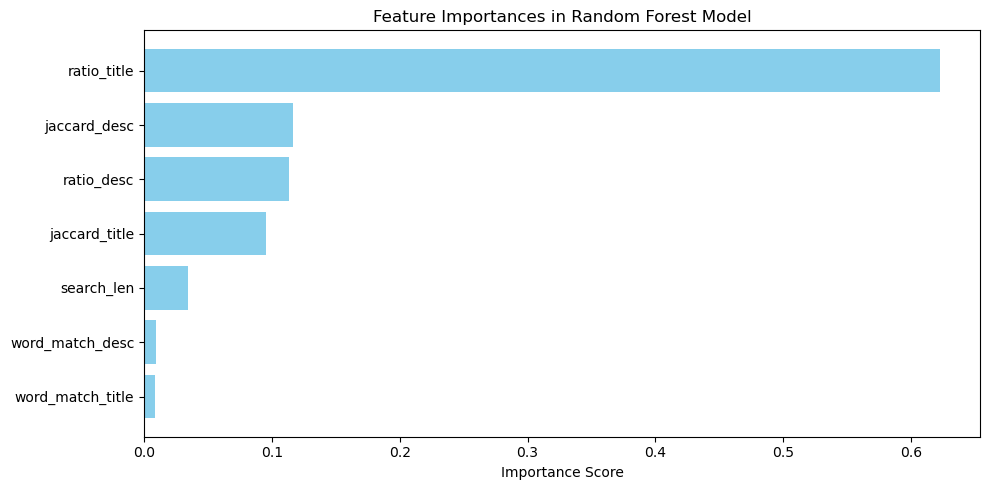

In [8]:
import matplotlib.pyplot as plt

print("Analyzing feature importances...")

# Get importance scores from the trained model
importances = model.feature_importances_

# Create a DataFrame for visualization
importance_df = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': importances
}).sort_values(by='Importance', ascending=True)

# Plot the feature importances
plt.figure(figsize=(10, 5))
plt.barh(importance_df['Feature'], importance_df['Importance'], color='skyblue')
plt.xlabel('Importance Score')
plt.title('Feature Importances in Random Forest Model')
plt.tight_layout()
plt.show()

### saving model

In [9]:
import pickle

print("Saving the model and components...")

# Create a dictionary to save our trained model and the feature list
model_data = {
    'trained_model': model,
    'features': feature_cols
}

# Save to a binary file
with open('ir_search_model.pkl', 'wb') as f:
    pickle.dump(model_data, f)

print("Model saved successfully as 'ir_search_model.pkl'!")

Saving the model and components...
Model saved successfully as 'ir_search_model.pkl'!
